# 01 — Exploratory Data Analysis: RetailPulse / Olist

Bu notebook Gold sipariş havuzunun sağlık kontrollerini, tekrar satın alma davranışını, zaman hacmini, lojistik performansını ve müşteri memnuniyetini inceler. Amaç yalnızca grafik üretmek değil; churn modelinde repeat müşteri kohortunu ve Sliding Window (Temporal Pooling) yaklaşımını veriden gerekçelendirmektir.

> **Bağlantı notu:** İstenen bağlantı localhost:5434/retailpulse_db. Bu repo içindeki .env.example varsayılanı retailpulse veritabanıdır. Aşağıdaki hücre önce POWERBI_DB_NAME değerini, sonra .env içindeki DB_NAME değerini, son olarak retailpulse_db varsayılanını kullanır. İstenen DB adı varsa POWERBI_DB_NAME=retailpulse_db ayarlayın. Gold fact_orders içinde ödeme alanı total_payment olarak saklanır; silver.order_reviews, Gold sipariş anahtarı ve gold.dim_customers üzerinden ilgili review ve müşteri bilgileri eklenir.

In [1]:
# Gerekirse notebook kernel'inde bir kez çalıştırın:
# %pip install pandas sqlalchemy "psycopg[binary]" python-dotenv matplotlib seaborn

import os
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from dotenv import load_dotenv
from sqlalchemy import URL, create_engine, text
from IPython.display import display

sns.set_theme(style="darkgrid", context="notebook")
plt.rcParams.update({
    "figure.facecolor": "#10141c",
    "axes.facecolor": "#171d29",
    "axes.edgecolor": "#64748b",
    "axes.labelcolor": "#e5e7eb",
    "text.color": "#e5e7eb",
    "xtick.color": "#cbd5e1",
    "ytick.color": "#cbd5e1",
    "grid.color": "#334155",
})

# Notebook notebooks/ altından açıldığında proje kökünü bul.
PROJECT_ROOT = Path.cwd()
if PROJECT_ROOT.name.lower() == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent
elif not (PROJECT_ROOT / ".env").exists() and (PROJECT_ROOT.parent / ".env").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent

load_dotenv(PROJECT_ROOT / ".env")
DB_HOST = os.getenv("DB_HOST", "localhost")
DB_PORT = int(os.getenv("DB_PORT", "5434"))
DB_NAME = os.getenv("POWERBI_DB_NAME", os.getenv("DB_NAME", "retailpulse_db"))
DB_USER = os.getenv("DB_USER", "postgres")
DB_PASSWORD = os.getenv("DB_PASSWORD", "postgres")

# URL.create parola içindeki @, :, / gibi karakterleri güvenli biçimde encode eder.
db_url = URL.create(
    "postgresql+psycopg",
    username=DB_USER,
    password=DB_PASSWORD,
    host=DB_HOST,
    port=DB_PORT,
    database=DB_NAME,
)
engine = create_engine(db_url, pool_pre_ping=True)

print(f"PostgreSQL: {DB_HOST}:{DB_PORT}/{DB_NAME}")
with engine.connect() as connection:
    print("Bağlantı başarılı:", connection.execute(text("SELECT current_database()")).scalar())

PostgreSQL: localhost:5434/retailpulse
Bağlantı başarılı: retailpulse


## Bölüm 1 — Genel sağlık ve boyut özeti

Sipariş başına tek satırlı analiz DataFrame'i; ödeme, müşteri eyaleti, teslimat, sipariş kalemleri/satıcı sayısı ve siparişin ortalama review skorunu birleştirir. Gold'da ayrı bir ödeme fact tablosu bulunmadığından total_payment, Silver ödemelerinden Gold fact'e önceden toplanmış sipariş tutarıdır.

In [2]:
ORDERS_SQL = """
WITH item_summary AS (
    SELECT
        i.order_id,
        COUNT(*)::integer AS item_count,
        COUNT(DISTINCT i.seller_id)::integer AS seller_count,
        COUNT(DISTINCT p.product_category_name)::integer AS category_count
    FROM gold.fact_order_items AS i
    LEFT JOIN gold.dim_products AS p ON p.product_id = i.product_id
    GROUP BY i.order_id
),
review_summary AS (
    SELECT order_id, AVG(review_score)::double precision AS avg_review_score
    FROM silver.order_reviews
    GROUP BY order_id
)
SELECT
    f.order_id,
    f.customer_id,
    f.customer_unique_id,
    COALESCE(c.customer_state, '(unknown)') AS customer_state,
    f.order_purchase_timestamp,
    f.order_approved_at,
    f.order_delivered_customer_date,
    f.order_estimated_delivery_date,
    f.order_status,
    f.total_product_amount,
    f.total_freight,
    f.total_payment AS payment_value,
    f.delivery_days,
    f.delivery_delay_days,
    COALESCE(i.item_count, 0) AS item_count,
    COALESCE(i.seller_count, 0) AS seller_count,
    COALESCE(i.category_count, 0) AS category_count,
    r.avg_review_score
FROM gold.fact_orders AS f
LEFT JOIN gold.dim_customers AS c
    ON c.customer_unique_id = f.customer_unique_id
LEFT JOIN item_summary AS i ON i.order_id = f.order_id
LEFT JOIN review_summary AS r ON r.order_id = f.order_id
"""

with engine.connect() as connection:
    orders = pd.read_sql_query(text(ORDERS_SQL), connection)
    dimensions = pd.read_sql_query(
        text("""
            SELECT
                COUNT(DISTINCT i.seller_id) AS seller_count,
                COUNT(DISTINCT p.product_category_name) AS category_count
            FROM gold.fact_order_items AS i
            LEFT JOIN gold.dim_products AS p ON p.product_id = i.product_id
        """),
        connection,
    ).iloc[0]

orders["order_purchase_timestamp"] = pd.to_datetime(orders["order_purchase_timestamp"])
for column in ["order_approved_at", "order_delivered_customer_date", "order_estimated_delivery_date"]:
    orders[column] = pd.to_datetime(orders[column])
for column in [
    "total_product_amount", "total_freight", "payment_value", "delivery_days",
    "delivery_delay_days", "avg_review_score"
]:
    orders[column] = pd.to_numeric(orders[column], errors="coerce")

print(f"DataFrame boyutu: {orders.shape[0]:,} sipariş × {orders.shape[1]} kolon")
display(orders.head())

DataFrame boyutu: 99,092 sipariş × 18 kolon


,order_id,customer_id,customer_unique_id,customer_state,order_purchase_timestamp,order_approved_at,order_delivered_customer_date,order_estimated_delivery_date,order_status,total_product_amount,total_freight,payment_value,delivery_days,delivery_delay_days,item_count,seller_count,category_count,avg_review_score
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,7c396fd4830fd04220f754e42b4e5bff,SP,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-10 21:25:13,2017-10-18,delivered,29.99,8.72,38.71,8.4366,-7.1075,1,1,1,4.0
1,5ff96c15d0b717ac6ad1f3d77225a350,19402a48fe860416adf93348aba37740,e2dfa3127fedbbca9707b36304996dab,SP,2018-07-25 17:44:10,2018-07-25 17:55:14,2018-07-30 15:52:25,2018-08-08,delivered,19.90,12.80,32.70,4.9224,-8.3386,1,1,1,5.0
2,dcb36b511fcac050b97cd5c05de84dc3,3b6828a50ffe546942b7a473d70ac0fc,ccafc1c3f270410521c3c6f3b249870f,GO,2018-06-07 19:03:12,2018-06-12 23:31:02,2018-06-21 15:34:32,2018-07-04,delivered,132.40,14.05,146.45,13.8551,-12.3510,1,1,1,5.0
3,1790eea0b567cf50911c057cf20f90f9,52142aa69d8d0e1247ab0cada0f76023,a6fefcd9f434474cf6fcd8ed1102fd63,PE,2018-04-16 21:15:39,2018-04-16 22:10:26,2018-05-05 12:28:34,2018-05-15,delivered,186.90,38.00,224.90,18.6340,-9.4802,1,1,1,1.0
4,68873cf91053cd11e6b49a766db5af1a,4632eb5a8f175f6fe020520ae0c678f3,6da92ae920ab16fc4eceb8fcd7bd43ce,SP,2017-11-30 22:02:15,2017-12-02 02:51:18,2017-12-05 20:28:40,2017-12-18,delivered,79.90,11.76,91.66,4.9350,-12.1468,1,1,1,4.0


In [3]:
summary = pd.DataFrame(
    {
        "Metrik": [
            "Toplam sipariş",
            "Tekil müşteri",
            "Tekil satıcı",
            "Ürün kategorisi",
            "İlk sipariş tarihi",
            "Son sipariş tarihi",
        ],
        "Değer": [
            f"{orders['order_id'].nunique():,}",
            f"{orders['customer_unique_id'].nunique():,}",
            f"{int(dimensions['seller_count']):,}",
            f"{int(dimensions['category_count']):,}",
            str(orders["order_purchase_timestamp"].min().date()),
            str(orders["order_purchase_timestamp"].max().date()),
        ],
    }
)
display(summary)

missing = (
    orders.isna().sum()
    .rename("missing_count")
    .to_frame()
    .assign(missing_pct=lambda x: (100 * x["missing_count"] / len(orders)).round(2))
    .sort_values("missing_pct", ascending=False)
)
display(missing)

# IQR sınırlarının dışında kalan gözlem sayıları: bu bir inceleme bayrağıdır, otomatik silme değildir.
outlier_rows = []
for column in ["payment_value", "delivery_days", "delivery_delay_days", "item_count"]:
    values = pd.to_numeric(orders[column], errors="coerce").dropna()
    q1, q3 = values.quantile([0.25, 0.75])
    iqr = q3 - q1
    lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    outlier_rows.append({
        "metric": column,
        "valid_n": len(values),
        "lower_iqr_fence": lower,
        "upper_iqr_fence": upper,
        "outlier_count": int(((values < lower) | (values > upper)).sum()),
        "outlier_pct": round(100 * ((values < lower) | (values > upper)).mean(), 2),
    })
display(pd.DataFrame(outlier_rows).set_index("metric").round(2))

,Metrik,Değer
0,Toplam sipariş,"99,092"
1,Tekil müşteri,"95,774"
2,Tekil satıcı,"3,068"
3,Ürün kategorisi,73
4,İlk sipariş tarihi,2017-01-05
5,Son sipariş tarihi,2018-08-31


,missing_count,missing_pct
delivery_delay_days,2888,2.91
order_delivered_customer_date,2888,2.91
delivery_days,2888,2.91
avg_review_score,762,0.77
order_approved_at,135,0.14
order_id,0,0.00
customer_id,0,0.00
order_purchase_timestamp,0,0.00
customer_state,0,0.00
customer_unique_id,0,0.00


,valid_n,lower_iqr_fence,upper_iqr_fence,outlier_count,outlier_pct
metric,,,,,
payment_value,99092,-110.31,349.18,7826,7.90
delivery_days,96204,-6.63,29.07,4917,5.11
delivery_delay_days,96204,-30.99,8.39,4684,4.87
item_count,99092,1.00,1.00,10506,10.60


**Business / Engineering Insight.** Eksik teslimat/review alanları çoğunlukla siparişin henüz teslim edilmemiş veya değerlendirilmemiş olmasını yansıtabilir; modelleme öncesinde bu eksikleri otomatik olarak sıfıra çevirmeyin. IQR bulguları uç tutar ve uzun teslimat kuyruklarını incelemek içindir; gerçek yüksek değerleri doğrulamadan silmek ciro ve lojistik analizini aşağı yönlü yanlılaştırabilir.

## Bölüm 2 — Müşteri davranışı ve repeat customer kohort gerekçesi

Bir sipariş vermiş müşteriler ile en az iki sipariş verenleri ayırıyoruz. Churn modelinin hedefi tekrar satın alma davranışını öngördüğünden, tek siparişli müşterilerde gözlemlenmiş müşteri içi tekrar sıklığı ve siparişler arası süre bilgisi yoktur.

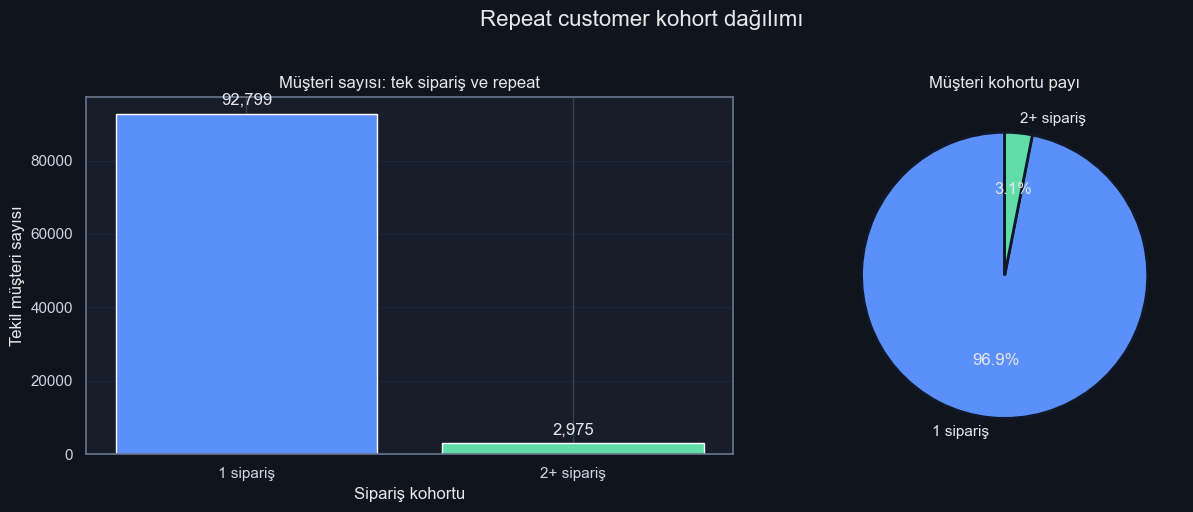

Repeat customer oranı: 3.1%


In [4]:
customer_order_counts = (
    orders.dropna(subset=["customer_unique_id"])
    .groupby("customer_unique_id")["order_id"]
    .nunique()
)
customer_order_groups = pd.Series(
    np.where(customer_order_counts.eq(1), "1 sipariş", "2+ sipariş"),
    index=customer_order_counts.index,
    name="cohort",
)
cohort_counts = customer_order_groups.value_counts().reindex(["1 sipariş", "2+ sipariş"]).fillna(0).astype(int)

fig, axes = plt.subplots(1, 2, figsize=(13, 5), gridspec_kw={"width_ratios": [1.2, 1]})
bars = axes[0].bar(cohort_counts.index, cohort_counts.values, color=["#5B8FF9", "#61DDAA"])
axes[0].set_title("Müşteri sayısı: tek sipariş ve repeat")
axes[0].set_xlabel("Sipariş kohortu")
axes[0].set_ylabel("Tekil müşteri sayısı")
axes[0].bar_label(bars, labels=[f"{v:,}" for v in cohort_counts.values], padding=4)
axes[0].grid(axis="y", alpha=0.25)

axes[1].pie(
    cohort_counts.values,
    labels=cohort_counts.index,
    autopct="%1.1f%%",
    startangle=90,
    colors=["#5B8FF9", "#61DDAA"],
    wedgeprops={"edgecolor": "#111827", "linewidth": 2},
)
axes[1].set_title("Müşteri kohortu payı")
fig.suptitle("Repeat customer kohort dağılımı", fontsize=16, y=1.02)
fig.tight_layout()
plt.show()

print(f"Repeat customer oranı: {(customer_order_counts.ge(2).mean()):.1%}")

**Business / Engineering Insight.** Tek siparişli müşteri, churn modelinin öğrenmeye çalıştığı müşteri içi tekrar aralığına sahip değildir; bu nedenle repeat davranışını modellemek için en az iki geçmiş sipariş şartı kullanılır. Bu seçim tüm müşteri tabanını temsil eden bir churn oranı değil, tekrar satın alan müşteri kohortu için bir model tanımıdır.

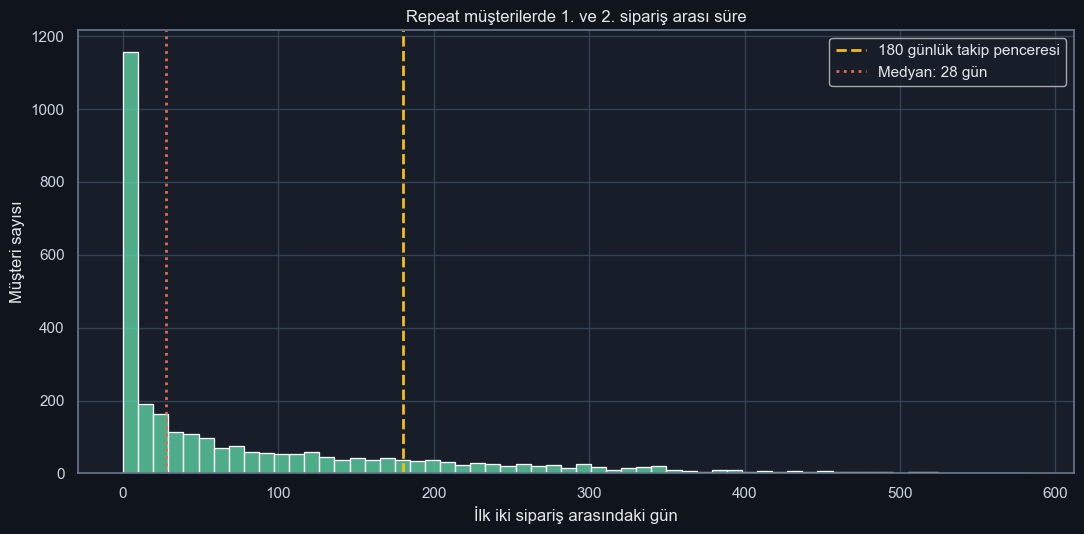

İlk iki sipariş farkı: n=2,975, medyan=27.9 gün, 90. yüzdelik=246.1 gün, 180 günde tekrar=83.0%


In [5]:
first_two = (
    orders.dropna(subset=["customer_unique_id", "order_purchase_timestamp"])
    .sort_values(["customer_unique_id", "order_purchase_timestamp"])
    .groupby("customer_unique_id")["order_purchase_timestamp"]
    .apply(lambda s: (s.iloc[1] - s.iloc[0]).total_seconds() / 86400 if len(s) >= 2 else np.nan)
    .dropna()
)
first_two = first_two[first_two >= 0]

fig, ax = plt.subplots(figsize=(11, 5.5))
sns.histplot(first_two, bins=60, color="#61DDAA", edgecolor=None, ax=ax)
ax.axvline(180, color="#F6BD16", linestyle="--", linewidth=2, label="180 günlük takip penceresi")
ax.axvline(first_two.median(), color="#E8684A", linestyle=":", linewidth=2, label=f"Medyan: {first_two.median():.0f} gün")
ax.set_title("Repeat müşterilerde 1. ve 2. sipariş arası süre")
ax.set_xlabel("İlk iki sipariş arasındaki gün")
ax.set_ylabel("Müşteri sayısı")
ax.legend()
plt.tight_layout()
plt.show()

within_180 = (first_two <= 180).mean()
print(
    f"İlk iki sipariş farkı: n={len(first_two):,}, medyan={first_two.median():.1f} gün, "
    f"90. yüzdelik={first_two.quantile(.90):.1f} gün, 180 günde tekrar={within_180:.1%}"
)

**Business / Engineering Insight.** Histogramdaki yoğunluk ve yazdırılan medyan/90. yüzdelik, 180 gün içinde tekrarın ne kadarının gözlenebildiğini gösterir. 180 gün, uzun kuyruklu satın alma aralıklarının bir bölümünü yakalarken takip ufkunu sınırlayan operasyonel bir seçimdir; grafik bu kararı ölçülebilir kılar, her müşterinin 180 günde tekrar edeceğini varsaymaz.

## Bölüm 3 — Zaman serisi ve hacim trendi: Sliding Window gerekçesi

Olist sipariş kapsamı 2016–2018 dönemine yayılır. Aylık sipariş adedi ve Gold fact içindeki toplam ödeme tutarı aynı grafikte ayrı ölçeklerle gösterilir.

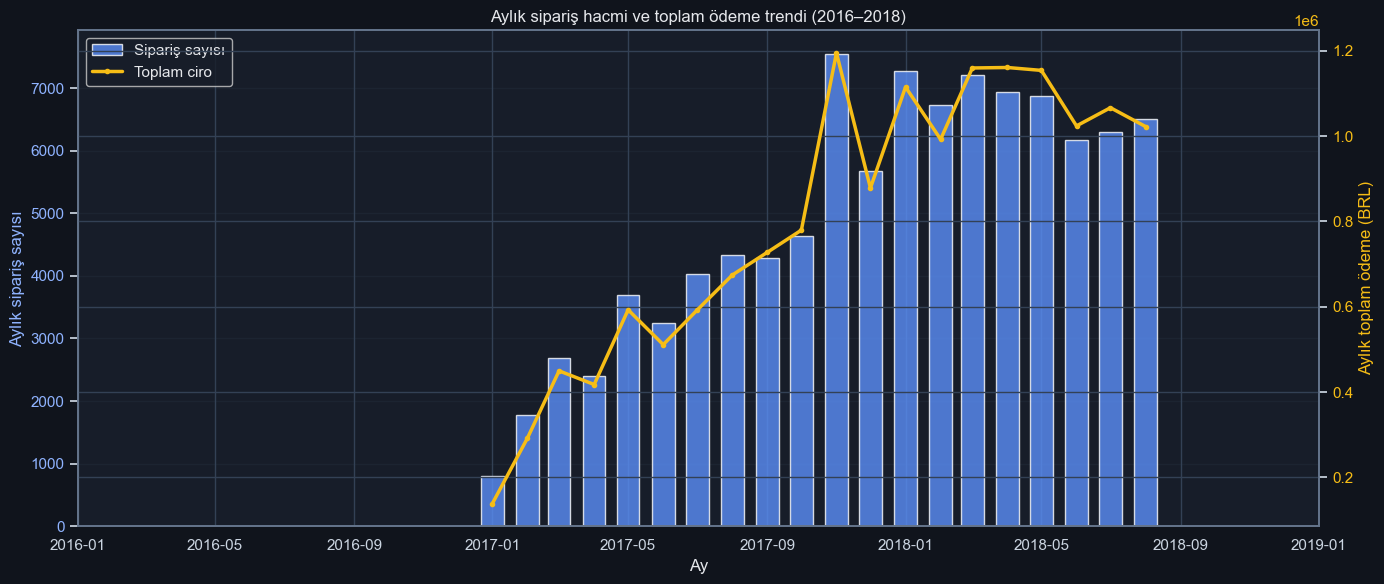

,order_count
order_purchase_timestamp,
2017,45101
2018,53991


In [6]:
monthly = (
    orders.dropna(subset=["order_purchase_timestamp"])
    .set_index("order_purchase_timestamp")
    .resample("MS")
    .agg(
        order_count=("order_id", "nunique"),
        total_revenue=("payment_value", "sum"),
    )
)
monthly = monthly.loc["2016-01":"2018-12"]

fig, ax_orders = plt.subplots(figsize=(14, 6))
ax_orders.bar(monthly.index, monthly["order_count"], width=20, color="#5B8FF9", alpha=0.8, label="Sipariş sayısı")
ax_orders.set_xlabel("Ay")
ax_orders.set_ylabel("Aylık sipariş sayısı", color="#8FB3FF")
ax_orders.tick_params(axis="y", labelcolor="#8FB3FF")
ax_orders.grid(axis="y", alpha=0.2)

ax_revenue = ax_orders.twinx()
ax_revenue.plot(monthly.index, monthly["total_revenue"], color="#F6BD16", linewidth=2.5, marker="o", markersize=3, label="Toplam ciro")
ax_revenue.set_ylabel("Aylık toplam ödeme (BRL)", color="#F6BD16")
ax_revenue.tick_params(axis="y", labelcolor="#F6BD16")
ax_orders.set_title("Aylık sipariş hacmi ve toplam ödeme trendi (2016–2018)")
ax_orders.set_xlim(pd.Timestamp("2016-01-01"), pd.Timestamp("2019-01-01"))
h1, l1 = ax_orders.get_legend_handles_labels()
h2, l2 = ax_revenue.get_legend_handles_labels()
ax_orders.legend(h1 + h2, l1 + l2, loc="upper left")
fig.tight_layout()
plt.show()

yearly_volume = orders.groupby(orders["order_purchase_timestamp"].dt.year)["order_id"].nunique()
display(yearly_volume.rename("order_count").to_frame())

**Business / Engineering Insight.** 2017 sonu ve 2018 başındaki yoğun dönemi grafikte karşılaştırın: tek snapshot tarihi kohort boyutunu ve mevsimsel davranış çeşitliliğini sınırlayabilir. Bu nedenle repeat müşterilerin daha yoğun olduğu 2017-10-01, 2017-12-15 ve 2018-03-04 kesitleri 180 günlük takip aralığıyla havuzlanır; müşteri bazlı GroupShuffleSplit aynı müşterinin train ve test'e sızmasını engeller.

## Bölüm 4 — Lojistik performans ve müşteri memnuniyeti

Eyalet karşılaştırması ortalama teslimat günü ve pozitif gecikme gününe sahip sipariş oranını gösterir. Review analizi yalnızca review bulunan ve teslimat gecikme değeri hesaplanabilen siparişleri kullanır.

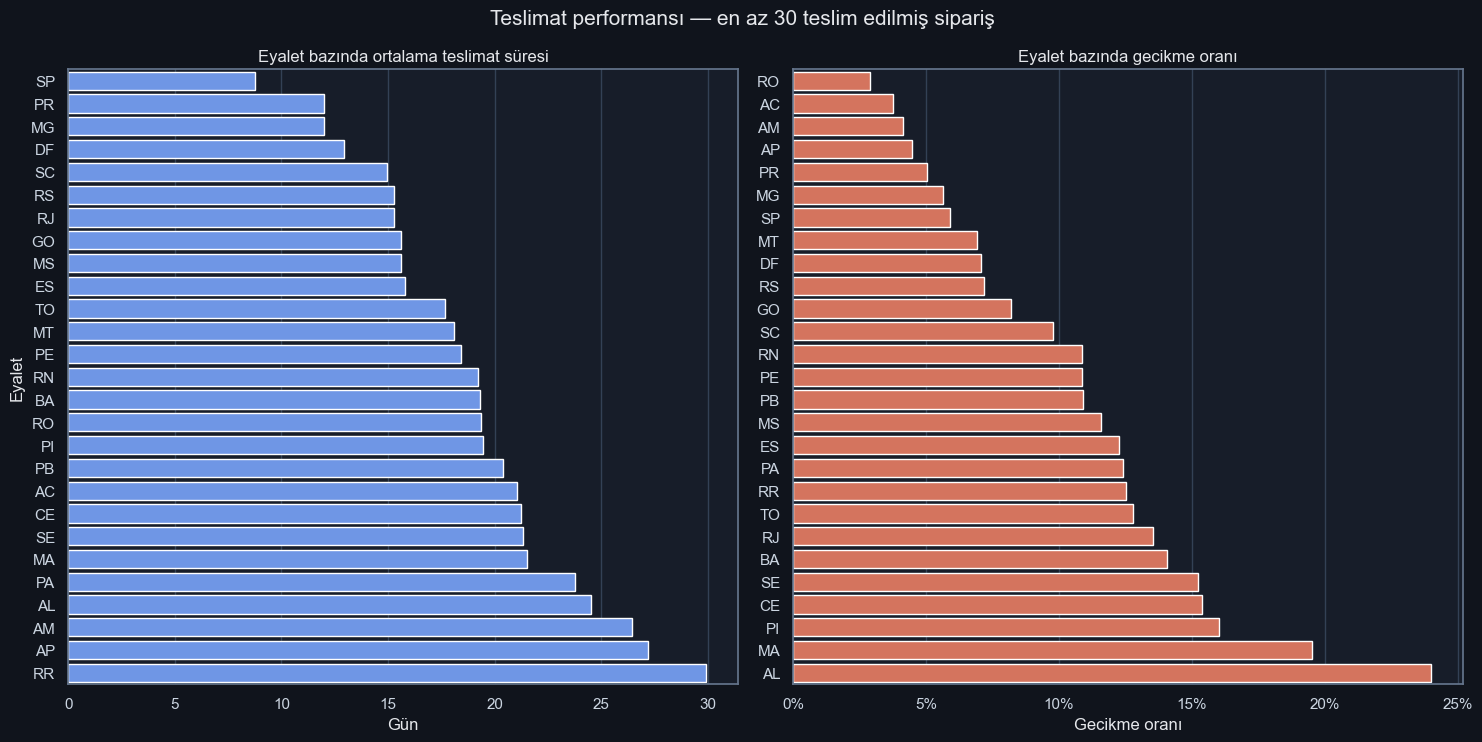

,orders_with_delivery,avg_delivery_days,late_rate
customer_state,,,
SP,40399,8.7,0.059
PR,4903,12.0,0.050
MG,11318,12.0,0.056
DF,2073,12.9,0.070
SC,3538,14.9,0.098
RS,5329,15.3,0.072
RJ,12303,15.3,0.135
GO,1953,15.6,0.082
MS,700,15.6,0.116


In [7]:
delivery = orders.dropna(subset=["customer_state", "delivery_days"]).copy()
state_delivery = (
    delivery.groupby("customer_state")
    .agg(
        orders_with_delivery=("order_id", "nunique"),
        avg_delivery_days=("delivery_days", "mean"),
        late_rate=("delivery_delay_days", lambda s: (s.dropna() > 0).mean() if s.notna().any() else np.nan),
    )
    .query("orders_with_delivery >= 30")
    .sort_values("avg_delivery_days", ascending=True)
)

fig, axes = plt.subplots(1, 2, figsize=(15, max(6, 0.28 * len(state_delivery))))
sns.barplot(data=state_delivery.reset_index(), x="avg_delivery_days", y="customer_state", color="#5B8FF9", ax=axes[0])
axes[0].set_title("Eyalet bazında ortalama teslimat süresi")
axes[0].set_xlabel("Gün")
axes[0].set_ylabel("Eyalet")

late_plot = state_delivery.reset_index().sort_values("late_rate", ascending=True)
sns.barplot(data=late_plot, x="late_rate", y="customer_state", color="#E8684A", ax=axes[1])
axes[1].set_title("Eyalet bazında gecikme oranı")
axes[1].set_xlabel("Gecikme oranı")
axes[1].set_ylabel("")
axes[1].xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{x:.0%}"))
fig.suptitle("Teslimat performansı — en az 30 teslim edilmiş sipariş", fontsize=15)
fig.tight_layout()
plt.show()

display(state_delivery.round({"avg_delivery_days": 1, "late_rate": 3}))

**Business / Engineering Insight.** Ortalama teslimat günü ve gecikme oranı farklı operasyonel sinyallerdir: uzak bir eyalette teslimat uzun olabilir ama tahmini tarihe uyabilir. Minimum 30 teslimat filtresi küçük örnekli eyaletlerin sıralamayı yanıltmasını azaltır; sonucu tüm sevkiyat evreni için mutlak performans gibi yorumlamayın.

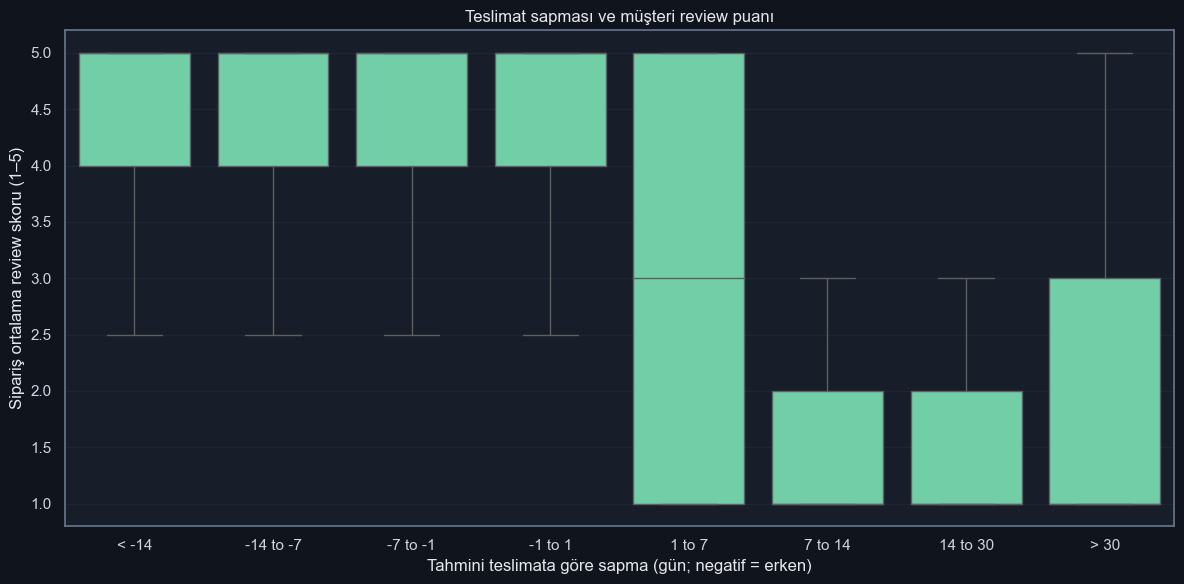

,orders,mean_review,median_review
delay_bucket,,,
< -14,34526,4.32,5.0
-14 to -7,36147,4.31,5.0
-7 to -1,15780,4.21,5.0
-1 to 1,2729,4.10,5.0
1 to 7,3128,2.84,3.0
7 to 14,1749,1.75,1.0
14 to 30,1160,1.62,1.0
> 30,342,2.03,1.0


In [8]:
review_delivery = orders.dropna(subset=["delivery_delay_days", "avg_review_score"]).copy()
bins = [-np.inf, -14, -7, -1, 1, 7, 14, 30, np.inf]
labels = ["< -14", "-14 to -7", "-7 to -1", "-1 to 1", "1 to 7", "7 to 14", "14 to 30", "> 30"]
review_delivery["delay_bucket"] = pd.cut(
    review_delivery["delivery_delay_days"],
    bins=bins,
    labels=labels,
    right=False,
    ordered=True,
)
fig, ax = plt.subplots(figsize=(12, 6))
sns.boxplot(
    data=review_delivery,
    x="delay_bucket",
    y="avg_review_score",
    color="#61DDAA",
    showfliers=False,
    ax=ax,
)
ax.set_title("Teslimat sapması ve müşteri review puanı")
ax.set_xlabel("Tahmini teslimata göre sapma (gün; negatif = erken)")
ax.set_ylabel("Sipariş ortalama review skoru (1–5)")
ax.set_ylim(0.8, 5.2)
ax.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()

display(
    review_delivery.groupby("delay_bucket", observed=True)
    .agg(orders=("order_id", "nunique"), mean_review=("avg_review_score", "mean"), median_review=("avg_review_score", "median"))
    .round(2)
)

**Business / Engineering Insight.** Kutu grafiği gecikme büyüdükçe puan dağılımının ve medyanın değişip değişmediğini gösterir; review gözlenmeyen siparişler bu grafikte yer almaz. Bu ilişki korelasyonel bir bulgudur, teslimat gecikmesinin tek başına düşük puana neden olduğunu kanıtlamaz.

## Bölüm 5 — Öznitelik korelasyonu

Müşteri düzeyinde recency, frequency, monetary, ortalama sepet/ödeme ve review skorunu hesaplayıp Spearman korelasyonunu inceliyoruz. Spearman, çarpık parasal dağılımlarda doğrusal ilişki varsayımı gerektirmediği için tercih edilmiştir.

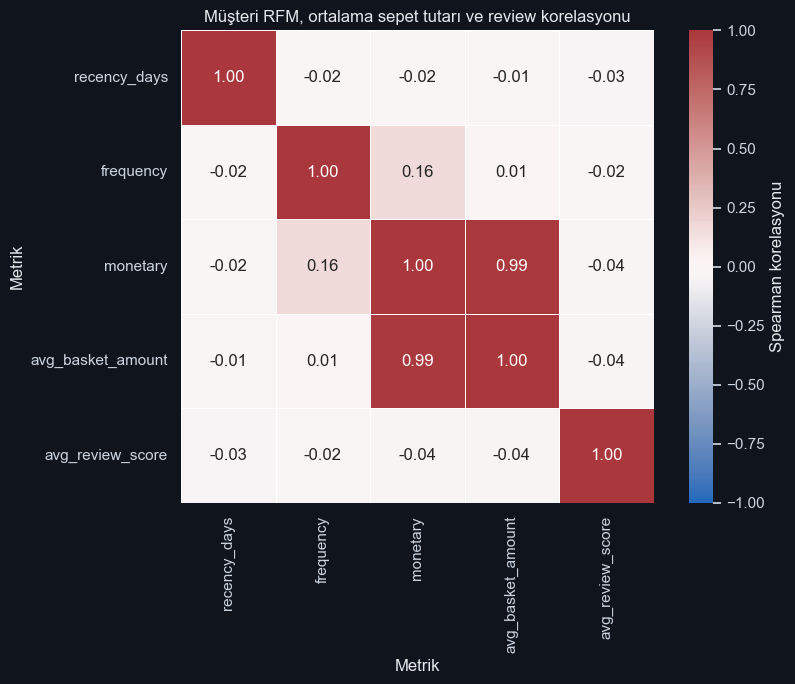

,recency_days,frequency,monetary,avg_basket_amount,avg_review_score
recency_days,1.000,-0.020,-0.015,-0.012,-0.031
frequency,-0.020,1.000,0.164,0.012,-0.019
monetary,-0.015,0.164,1.000,0.986,-0.045
avg_basket_amount,-0.012,0.012,0.986,1.000,-0.043
avg_review_score,-0.031,-0.019,-0.045,-0.043,1.000


In [9]:
customer_features = (
    orders.dropna(subset=["customer_unique_id", "order_purchase_timestamp"])
    .groupby("customer_unique_id")
    .agg(
        last_order=("order_purchase_timestamp", "max"),
        frequency=("order_id", "nunique"),
        monetary=("payment_value", "sum"),
        avg_basket_amount=("payment_value", "mean"),
        avg_review_score=("avg_review_score", "mean"),
    )
)
reference_date = orders["order_purchase_timestamp"].max().normalize() + pd.Timedelta(days=1)
customer_features["recency_days"] = (reference_date - customer_features["last_order"].dt.normalize()).dt.days
corr_columns = [
    "recency_days", "frequency", "monetary", "avg_basket_amount", "avg_review_score"
]
correlation = customer_features[corr_columns].corr(method="spearman")

fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(
    correlation,
    annot=True,
    fmt=".2f",
    cmap="vlag",
    center=0,
    vmin=-1,
    vmax=1,
    square=True,
    linewidths=0.7,
    cbar_kws={"label": "Spearman korelasyonu"},
    ax=ax,
)
ax.set_title("Müşteri RFM, ortalama sepet tutarı ve review korelasyonu")
ax.set_xlabel("Metrik")
ax.set_ylabel("Metrik")
plt.tight_layout()
plt.show()

display(correlation.round(3))

**Business / Engineering Insight.** Korelasyon, hangi müşteri sinyallerinin birlikte hareket ettiğini ve olası özellik fazlalığını belirlemeye yardımcı olur; nedensellik veya tek başına model önemini göstermez. Özellikle monetary ve average basket ilişkisini yorumlarken müşteri frequency'sini de göz önünde bulundurun; çok sipariş veren müşterinin toplam harcaması doğal olarak yükselir.

## Tekrar üretilebilirlik ve yorumlama notları

- Sipariş, ödeme, müşteri, ürün, teslimat ve review alanları SQLAlchemy ile tek sipariş-grain DataFrame'de birleştirilir; seller ve kategori sayıları Gold order items/product dimension üzerinden tamamlanır.
- Notebook veri değiştirmez; yalnızca Gold/Silver tablolardan okur.
- Para alanları veri setinde BRL cinsindendir; USD dönüşümü bu notebook'un kapsamına dahil değildir.
- Repeat müşteri kohortu ve 180 gün seçimi modelleme stratejisidir. Grafiklerdeki tarih aralıklarını, order status filtresini ve gözlenebilir takip sonunu iş kararında açıkça belirtin.
- Veritabanı adı bu projede retailpulse olarak ayarlı. retailpulse_db kullanmak istiyorsanız notebook kernel'inde POWERBI_DB_NAME ortam değişkenini ayarlayın.